[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Tnecniv-Teikram/NSA-hyperspectral-course-2026/blob/main/13_feature_extraction_dim_reduction.ipynb)

*Running in Colab? Run the setup cell below first — it clones the course and installs what this notebook needs. Running locally? It does nothing.*

# 🧬 Feature Extraction & Dimensionality Reduction
### Space Academy 2026 · Hyperspectral course · Week 2 — Feature extraction and dimensionality reduction (Lecture)

A Tanager pixel is a vector of **352 usable reflectance values**. That's what makes hyperspectral data powerful, and also what makes it awkward: neighbouring bands are nearly identical, noise is spread across all of them, and many machine-learning methods struggle when there are more features than well-labelled training pixels.

This lecture notebook shows the two families of solutions:

1. **Feature extraction**: build *new*, compact features from all bands (PCA, MNF, derivatives, narrow-band indices, absorption-band depths).
2. **Feature selection**: keep a *subset* of the original bands (and their physical meaning).

We end by assembling a **feature stack** that notebook 15 (classification) can use directly.

**What you will learn**
- Why hyperspectral bands are **redundant**, and the *Hughes phenomenon* (curse of dimensionality)
- **PCA**: variance-ordered components, loadings, and why "most variance" ≠ "most information"
- **MNF** (Minimum Noise Fraction): noise-whitened PCA, and **denoising** with the inverse transform
- **Band selection**: unsupervised (variance/correlation) and supervised (mutual information)
- **Derivative spectra** and the **red-edge position** (REP)
- **Narrow-band indices** and **absorption band depths** that multispectral sensors such as Sentinel-2 cannot compute
- How to combine it all into a compact, interpretable **feature stack**

**Prerequisites:** `10_spectral_signatures_and_libraries.ipynb`, `11_preprocessing.ipynb` (bad bands, noise). If you are not fluent with numpy arrays (axes, boolean masks, broadcasting), work through **`09_numpy_for_hyperspectral.ipynb`** first — it is 45–60 minutes and uses this same data.

**Data:** Konya, Türkiye (`20250608_091605_90_4001`): irrigated strip fields next to bare and fallow land. For mineral features also Korba, India (`20250219_053251_31_4001`) and Al Dhafra, UAE (`20250511_074311_00_4001`). `hu.get_scene()` uses the local HDF5 if it finds one and otherwise downloads it (~1 GB each) from Planet's STAC catalogue.

In [ ]:
# --- Setup: works both in Google Colab and in a local environment --------------------
# In Colab this clones the course repository, installs the geospatial packages that Colab
# does not ship, and moves into the course folder so the notebook finds hsi_utils and data/.
# Locally it does nothing at all — your own environment is already active.
import os
import pathlib
import subprocess
import sys

REPO = "Tnecniv-Teikram/NSA-hyperspectral-course-2026"          # change with: python tools/set_repo_url.py <owner>/<repo>

if "google.colab" in sys.modules:
    course = pathlib.Path("/content/hyperspectral-course")
    if not course.exists():
        subprocess.run(["git", "clone", "--depth", "1", "-q",
                        f"https://github.com/{REPO}.git", str(course)], check=True)
    os.chdir(course)
    sys.path.insert(0, str(course))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "h5py", "rasterio", "rioxarray", "xarray", "geopandas"], check=True)
    print("Colab ready — course at", course)
else:
    print("Local environment:", sys.executable.split("/")[-3])


In [1]:
# On Google Colab: upload hsi_utils.py next to this notebook and uncomment:
# %pip install -q h5py numpy scipy matplotlib scikit-learn pandas rasterio xarray rioxarray requests
import numpy as np
import matplotlib.pyplot as plt
import hsi_utils as hu

plt.rcParams["figure.dpi"] = 90
SEED = 42

## 1. The data: a 6 × 6 km window of irrigated fields

We read a 200 × 200 pixel window with all good bands (bad bands removed as in notebook 11) and reshape it into a **pixel matrix** $X$ with one row per pixel and one column per band. That's the shape every dimensionality-reduction method expects.

Cube (352, 200, 200)  →  pixel matrix X (39971, 352)  (99.9% of pixels complete)


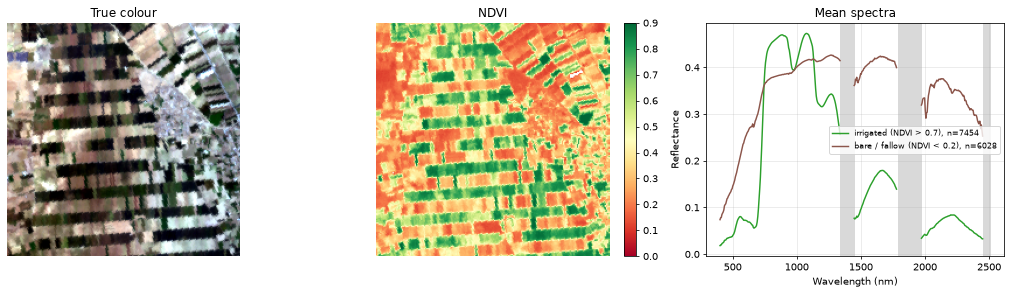

In [2]:
scene = hu.get_scene("20250608_091605_90_4001")
WINDOW = (300, 500, 400, 600)                 # (row_start, row_stop, col_start, col_stop)

cube, wl = scene.read_cube(WINDOW)            # (bands, rows, cols), NaN where invalid
X, ok = hu.cube_to_pixels(cube)               # (pixels, bands) + 2-D mask of complete pixels
n_bands, n_rows, n_cols = cube.shape
print(f"Cube {cube.shape}  →  pixel matrix X {X.shape}  ({ok.mean():.1%} of pixels complete)")

R = lambda nm: cube[hu.band_index(wl, nm)]    # shortcut: 2-D image of the band closest to nm
ndvi = hu.nd(R(860), R(665))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), dpi=70)
axes[0].imshow(hu.rgb_from_cube(cube, wl)); axes[0].set_title("True colour"); axes[0].axis("off")
im = axes[1].imshow(ndvi, cmap="RdYlGn", vmin=0, vmax=0.9); axes[1].set_title("NDVI"); axes[1].axis("off")
plt.colorbar(im, ax=axes[1], fraction=0.046)
for name, sel, col in (("irrigated (NDVI > 0.7)", ndvi > 0.7, "tab:green"),
                       ("bare / fallow (NDVI < 0.2)", ndvi < 0.2, "tab:brown")):
    hu.plot_spectrum(axes[2], wl, np.nanmean(cube[:, sel], axis=1), color=col, label=f"{name}, n={sel.sum()}")
hu.shade_bad_regions(axes[2])
axes[2].set_xlabel("Wavelength (nm)"); axes[2].set_ylabel("Reflectance"); axes[2].legend(loc="center right", fontsize=8)
axes[2].grid(alpha=0.3)
axes[2].set_title("Mean spectra")
plt.tight_layout(); plt.show()

## 2. Why reduce dimensions? Redundancy and the Hughes phenomenon

**Redundancy.** Tanager samples the spectrum every ~5 nm, but most surface reflectance spectra change slowly over tens of nanometres. Neighbouring bands therefore carry almost the same information. The **correlation matrix** of the 352 bands makes this visible.

**The Hughes phenomenon** (Hughes, 1968). With a fixed number of training samples, a classifier's accuracy first *increases* as you add features, then *decreases*, because the model has too many parameters to estimate reliably from the data. A Gaussian classifier needs a covariance matrix of $d(d+1)/2$ numbers: for $d = 352$ bands that's **62,128 parameters per class**. This is why feature extraction and selection matter so much for hyperspectral data, even in the deep-learning era.

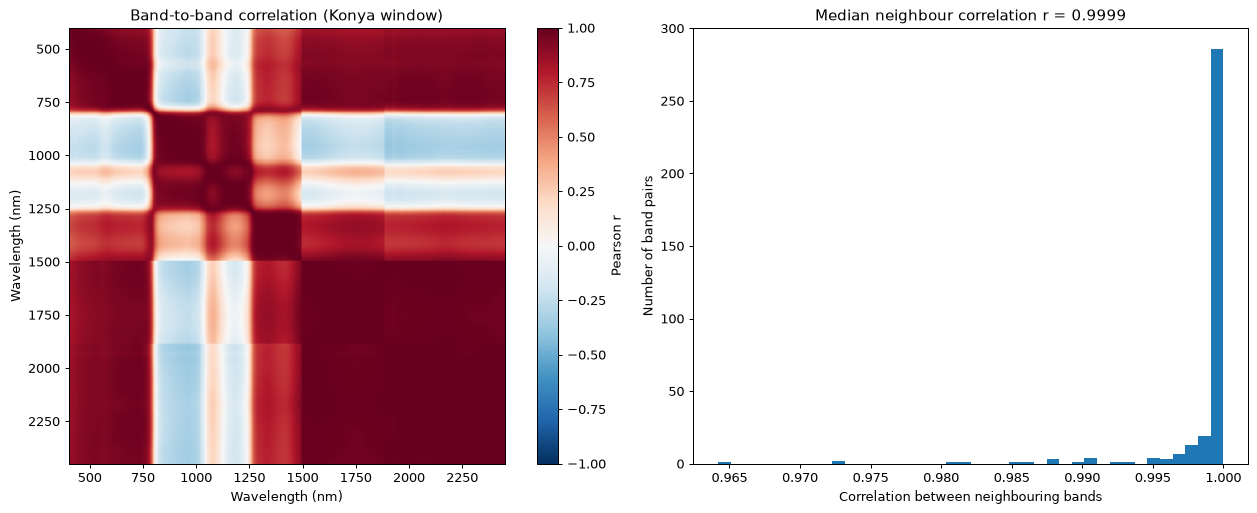

Parameters of one class covariance matrix: 62,128


In [3]:
rng = np.random.default_rng(SEED)
sample = X[rng.choice(len(X), size=5000, replace=False)]
C = np.corrcoef(sample, rowvar=False)
adjacent = np.array([C[i, i + 1] for i in range(n_bands - 1) if wl[i + 1] - wl[i] < 10])

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8), gridspec_kw={"width_ratios": [1.15, 1]})
im = axes[0].imshow(C, cmap="RdBu_r", vmin=-1, vmax=1, extent=[wl[0], wl[-1], wl[-1], wl[0]])
axes[0].set_title("Band-to-band correlation (Konya window)")
axes[0].set_xlabel("Wavelength (nm)"); axes[0].set_ylabel("Wavelength (nm)")
plt.colorbar(im, ax=axes[0], fraction=0.046, label="Pearson r")
axes[1].hist(adjacent, bins=40, color="tab:blue")
axes[1].set_xlabel("Correlation between neighbouring bands"); axes[1].set_ylabel("Number of band pairs")
axes[1].set_title(f"Median neighbour correlation r = {np.median(adjacent):.4f}")
plt.tight_layout(); plt.show()
print(f"Parameters of one class covariance matrix: {n_bands * (n_bands + 1) // 2:,}")

The matrix shows **blocks**. In this farmland the visible (400–700 nm) and SWIR (1450–2450 nm) bands behave alike: both are dark for green crops and bright for bare soil, so they are strongly correlated with each other. The **NIR plateau** (750–1300 nm) does the opposite (bright for crops) and correlates *negatively* with them. The flip happens at the red edge. Almost every pair of neighbouring bands has r > 0.99, so the effective dimensionality of this window is far below 352.

## 3. Principal Component Analysis (PCA)

PCA rotates the data onto new orthogonal axes, the **principal components**, ordered by how much variance they explain. Mathematically these are the eigenvectors $\mathbf{v}_k$ of the band covariance matrix $\Sigma$:

$$\Sigma\,\mathbf{v}_k = \lambda_k \mathbf{v}_k, \qquad \text{PC}_k = (\mathbf{x} - \bar{\mathbf{x}})^\top \mathbf{v}_k$$

$\lambda_k$ is the variance of component $k$. The **loadings** $\mathbf{v}_k$ show which wavelengths drive that component.

> ⚠️ Covariance-based PCA is dominated by bright, high-variance bands (NIR, SWIR). Standardising the bands first (correlation-based PCA) gives every band equal weight. Both are valid; be explicit about which one you use.

Explained variance, first 6 PCs: [87.81 10.37  0.91  0.42  0.14  0.12] %
PCs needed for 99 % / 99.9 % of the variance: 3 / 10


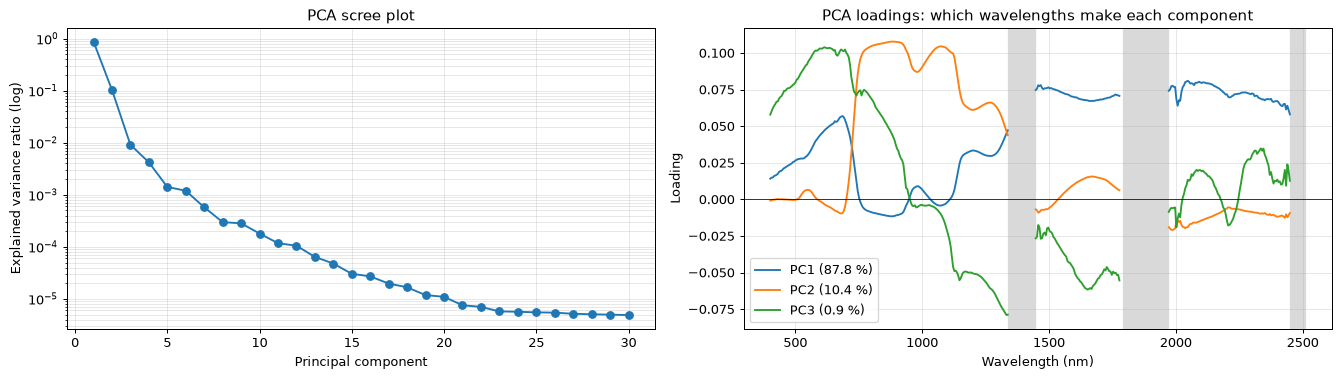

In [4]:
from sklearn.decomposition import PCA

pca = PCA(n_components=30, random_state=SEED).fit(X)
Z_pca = pca.transform(X)
evr = pca.explained_variance_ratio_
print("Explained variance, first 6 PCs:", np.round(evr[:6] * 100, 2), "%")
print(f"PCs needed for 99 % / 99.9 % of the variance: {np.searchsorted(np.cumsum(evr), 0.99) + 1} / "
      f"{np.searchsorted(np.cumsum(evr), 0.999) + 1}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
axes[0].semilogy(np.arange(1, 31), evr, "o-")
axes[0].set_xlabel("Principal component"); axes[0].set_ylabel("Explained variance ratio (log)")
axes[0].set_title("PCA scree plot"); axes[0].grid(alpha=0.3, which="both")
for k, col in zip(range(3), ("tab:blue", "tab:orange", "tab:green")):
    hu.plot_spectrum(axes[1], wl, pca.components_[k], color=col, label=f"PC{k + 1} ({evr[k] * 100:.1f} %)")
axes[1].axhline(0, color="k", lw=0.6); hu.shade_bad_regions(axes[1])
axes[1].set_xlabel("Wavelength (nm)"); axes[1].set_ylabel("Loading"); axes[1].legend(); axes[1].grid(alpha=0.3)
axes[1].set_title("PCA loadings: which wavelengths make each component")
plt.tight_layout(); plt.show()

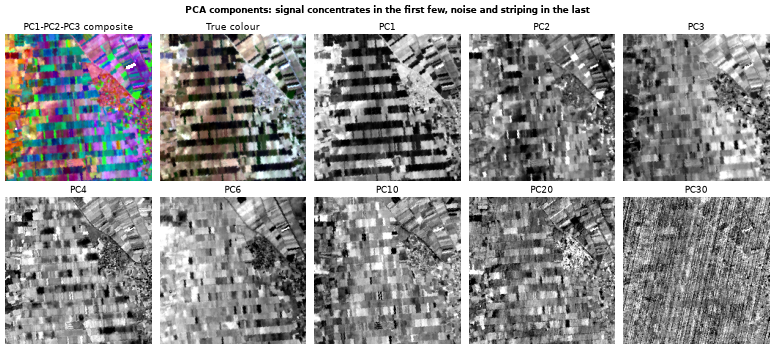

In [5]:
pc_imgs = hu.pixels_to_image(Z_pca, ok)            # (components, rows, cols)
show = [0, 1, 2, 3, 5, 9, 19, 29]
fig, axes = plt.subplots(2, 5, figsize=(15, 7.0), dpi=52)
axes = axes.ravel()
pc_rgb = hu.stretch(np.dstack([pc_imgs[0], pc_imgs[1], pc_imgs[2]]))
axes[0].imshow(pc_rgb); axes[0].set_title("PC1-PC2-PC3 composite")
axes[1].imshow(hu.rgb_from_cube(cube, wl)); axes[1].set_title("True colour")
for ax, k in zip(axes[2:], show):
    ax.imshow(hu.stretch(pc_imgs[k]), cmap="gray"); ax.set_title(f"PC{k + 1}")
for ax in axes:
    ax.axis("off")
plt.suptitle("PCA components: signal concentrates in the first few, noise and striping in the last", fontweight="bold")
plt.tight_layout(); plt.show()

**Reading the result.** PC1 is essentially overall **brightness** (almost all loadings positive, largest in the bright SWIR). PC2 is dominated by the **NIR plateau** and is near zero in the visible, a vegetation axis much like NDVI. PC3 contrasts the visible/NIR shoulder against the SWIR, a soil-moisture and dry-matter axis. Over 99 % of the variance sits in the first three components. That doesn't mean the rest is useless. Subtle but diagnostic features, such as the xanthophyll signal behind PRI or a weak clay absorption, have **low variance** and end up in higher components, mixed with noise. PCA ranks by variance, not by usefulness, and not by signal-to-noise. MNF fixes the last point.

## 4. Minimum Noise Fraction (MNF)

MNF (Green et al., 1988; Lee et al., 1990) is "PCA after making the noise white":

1. **Estimate the noise covariance** $\Sigma_N$. The classic trick is the **shift difference**: in a spatially *homogeneous* area neighbouring pixels share the same signal, so $\mathbf{x}_{i,j} - \mathbf{x}_{i,j+1}$ is (almost) pure noise, with covariance $2\Sigma_N$.
2. **Whiten the noise**: transform the data with $W = V_N \Lambda_N^{-1/2}$ (eigenvectors and eigenvalues of $\Sigma_N$), so the noise has unit variance in every direction and no correlation between bands.
3. **PCA on the whitened data.** Components are now ordered by **signal-to-noise ratio**: eigenvalue ≈ SNR + 1. Components with eigenvalue ≈ 1 are pure noise.

First we need a homogeneous area. We search the scene automatically for the 40 × 40 px window with the lowest coefficient of variation at 1650 nm.

> **If you skip the maths.** The whitening algebra below is worth understanding, but it is not required to use MNF.
> The working knowledge is: *MNF is PCA after making the noise equal in every band, so its first components are the
> ones with the best signal-to-noise, not merely the most variance.* In practice you need three things — run it,
> look at where the components stop showing structure and start showing noise, and keep that many as classifier
> input. Everything else on this page is explanation. Come back to it when you need to defend the choice.

Most homogeneous 40 × 40 window: (330, 370, 340, 380), coefficient of variation at 1650 nm = 0.029


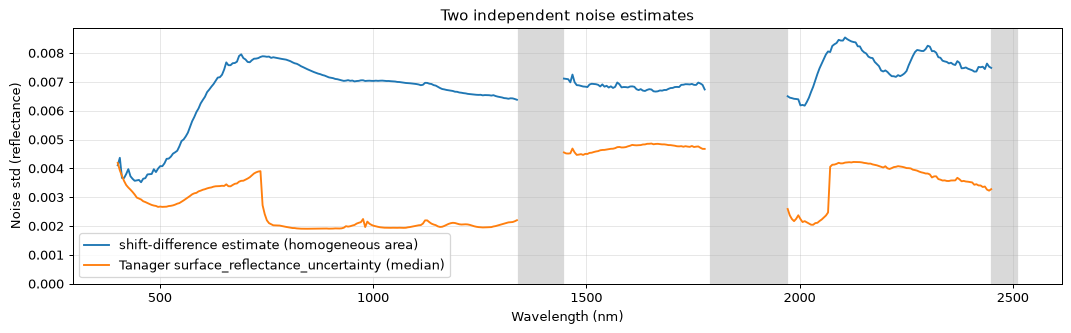

In [6]:
b1650 = scene.read_band(1650)
best = None
for r in range(0, b1650.shape[0] - 40, 10):
    for c in range(0, b1650.shape[1] - 40, 10):
        w = b1650[r:r + 40, c:c + 40]
        if np.isnan(w).any():
            continue
        cv = np.std(w) / np.mean(w)
        if best is None or cv < best[0]:
            best = (cv, r, c)
cv, r, c = best
HOMOG = (r, r + 40, c, c + 40)
print(f"Most homogeneous 40 × 40 window: {HOMOG}, coefficient of variation at 1650 nm = {cv:.3f}")

hcube, _ = scene.read_cube(HOMOG)
diffs = np.vstack([(hcube[:, :, 1:] - hcube[:, :, :-1]).reshape(n_bands, -1).T,   # horizontal
                   (hcube[:, 1:, :] - hcube[:, :-1, :]).reshape(n_bands, -1).T])  # vertical
diffs = diffs[np.all(np.isfinite(diffs), axis=1)]
Sigma_N = np.cov(diffs, rowvar=False) / 2.0
noise_std_shift = np.sqrt(np.diag(Sigma_N))

# Tanager also ships a per-pixel uncertainty estimate: a useful cross-check
unc, _ = scene.read_cube(HOMOG, dataset="surface_reflectance_uncertainty")
noise_std_file = np.nanmedian(unc.reshape(n_bands, -1), axis=1)

fig, ax = plt.subplots(figsize=(12, 3.8))
hu.plot_spectrum(ax, wl, noise_std_shift, label="shift-difference estimate (homogeneous area)")
hu.plot_spectrum(ax, wl, noise_std_file, label="Tanager surface_reflectance_uncertainty (median)")
hu.shade_bad_regions(ax); ax.set_ylim(0, None)
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("Noise std (reflectance)"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Two independent noise estimates")
plt.tight_layout(); plt.show()

The two estimates agree in the blue but differ by a factor of 1.5–3.5 in the NIR and SWIR. Even the "most homogeneous" 1.2 × 1.2 km area has some real spatial texture, and the shift difference counts that texture as noise, so it is an **upper bound**. The file's uncertainty is a *model-based* estimate from the calibration and the atmospheric correction. Either way, noise is of order 0.002–0.007 reflectance: small compared with signals of 0.05–0.5, but not negligible for subtle features.

**A numerical detail.** The noise covariance of Tanager reflectance is **nearly singular**: some eigenvalues are ~$10^{-15}$. Bands aren't fully independent after resampling and atmospheric correction. Dividing by $\sqrt{10^{-15}}$ would blow up meaningless directions, so we add a tiny **ridge** (0.1 % of the mean noise variance) to the diagonal before whitening. This is standard practice.

MNF eigenvalues (≈ SNR + 1), first 8: [64772  2040  1238  1116   372   316   176   133]
components with eigenvalue >   10: 26
components with eigenvalue >    3: 64
components with eigenvalue >  1.5: 114


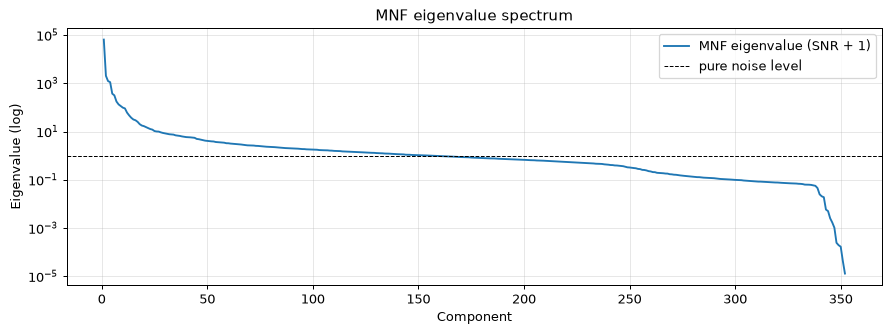

In [7]:
def mnf_fit(X, Sigma_N, ridge=1e-3):
    """Return (mean, forward transform T, eigenvalues) so that Z = (X - mean) @ T are the MNF components."""
    mean = X.mean(axis=0)
    S_n = Sigma_N + np.eye(len(Sigma_N)) * ridge * np.trace(Sigma_N) / len(Sigma_N)
    ev_n, V_n = np.linalg.eigh(S_n)
    W = V_n / np.sqrt(ev_n)                      # noise-whitening matrix
    Xw = (X - mean) @ W
    ev, V = np.linalg.eigh(np.cov(Xw, rowvar=False))
    order = np.argsort(ev)[::-1]
    return mean, W @ V[:, order], ev[order]


mnf_mean, T_mnf, mnf_eig = mnf_fit(X, Sigma_N)
Z_mnf = (X - mnf_mean) @ T_mnf
print("MNF eigenvalues (≈ SNR + 1), first 8:", np.round(mnf_eig[:8]).astype(int))
for thr in (10, 3, 1.5):
    print(f"components with eigenvalue > {thr:>4}: {(mnf_eig > thr).sum()}")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.semilogy(np.arange(1, n_bands + 1), mnf_eig, label="MNF eigenvalue (SNR + 1)")
ax.axhline(1, color="k", ls="--", lw=0.8, label="pure noise level")
ax.set_xlabel("Component"); ax.set_ylabel("Eigenvalue (log)"); ax.grid(alpha=0.3, which="both"); ax.legend()
ax.set_title("MNF eigenvalue spectrum")
plt.tight_layout(); plt.show()

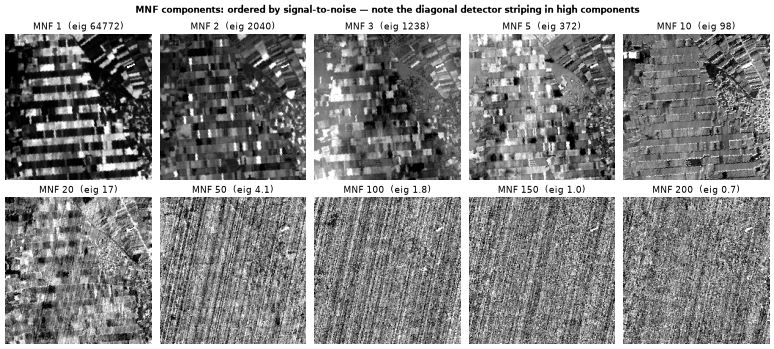

In [8]:
mnf_imgs = hu.pixels_to_image(Z_mnf[:, :200], ok)
show = [0, 1, 2, 4, 9, 19, 49, 99, 149, 199]
fig, axes = plt.subplots(2, 5, figsize=(15, 7.0), dpi=52)
for ax, k in zip(axes.ravel(), show):
    ax.imshow(hu.stretch(mnf_imgs[k]), cmap="gray")
    ax.set_title(f"MNF {k + 1}  (eig {mnf_eig[k]:.0f})" if mnf_eig[k] > 10 else f"MNF {k + 1}  (eig {mnf_eig[k]:.1f})")
    ax.axis("off")
plt.suptitle("MNF components: ordered by signal-to-noise — note the diagonal detector striping in high components",
             fontweight="bold")
plt.tight_layout(); plt.show()

Low-order MNF components show fields, soil patterns and the town. High-order components show **diagonal striping**. Tanager is a *push-broom* imager: each across-track pixel is seen by its own detector element, and slight differences in detector response leave stripes along the flight direction, diagonal here because the image is rotated to north-up. MNF puts this sensor artefact into its own components, where it is easy to remove.

### 4.1 MNF denoising

Keep the first $k$ components, set the rest to zero, and transform back: $\hat{X} = Z_{1..k}\,T^{-1}_{1..k} + \bar{\mathbf{x}}$. The noisiest parts of the spectrum, the blue end (410 nm) and the SWIR edge (2440 nm), benefit most.

Keeping K = 64 of 352 MNF components; median |change| = 0.0029 reflectance


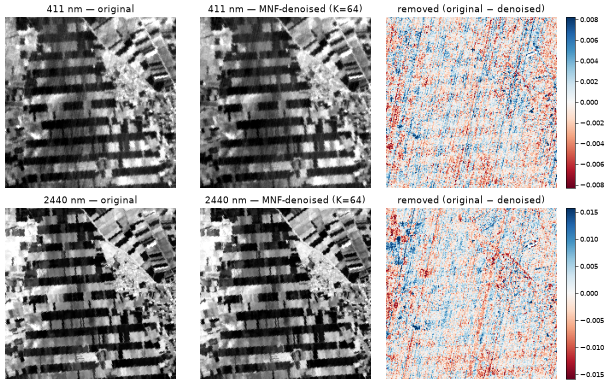

In [9]:
K = int((mnf_eig > 3).sum())                  # keep components with SNR ≳ 2
T_inv = np.linalg.inv(T_mnf)
X_denoised = Z_mnf[:, :K] @ T_inv[:K] + mnf_mean
print(f"Keeping K = {K} of {n_bands} MNF components; median |change| = {np.median(np.abs(X - X_denoised)):.4f} reflectance")

fig, axes = plt.subplots(2, 3, figsize=(12, 7.5), dpi=52)
for row, nm in zip(axes, (410, 2440)):
    b = hu.band_index(wl, nm)
    orig, den = hu.pixels_to_image(X[:, b], ok), hu.pixels_to_image(X_denoised[:, b], ok)
    lo, hi = np.nanpercentile(orig, [2, 98])
    row[0].imshow(orig, cmap="gray", vmin=lo, vmax=hi); row[0].set_title(f"{wl[b]:.0f} nm — original")
    row[1].imshow(den, cmap="gray", vmin=lo, vmax=hi); row[1].set_title(f"{wl[b]:.0f} nm — MNF-denoised (K={K})")
    res = orig - den
    lim = np.nanpercentile(np.abs(res), 99)
    im = row[2].imshow(res, cmap="RdBu", vmin=-lim, vmax=lim); row[2].set_title("removed (original − denoised)")
    plt.colorbar(im, ax=row[2], fraction=0.046)
    for ax in row:
        ax.axis("off")
plt.tight_layout(); plt.show()

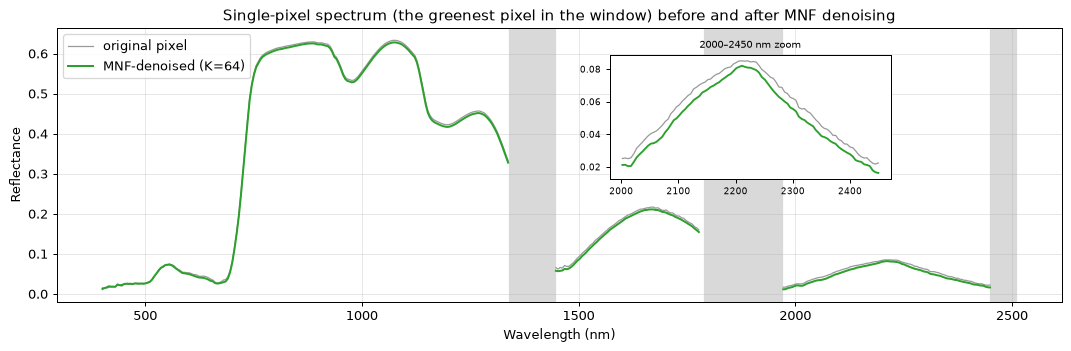

In [10]:
# One pixel on an irrigated field, before and after
pix = np.argmax(np.where(np.isfinite(ndvi[ok]), ndvi[ok], -1))
fig, ax = plt.subplots(figsize=(12, 4))
hu.plot_spectrum(ax, wl, X[pix], color="0.6", lw=1, label="original pixel")
hu.plot_spectrum(ax, wl, X_denoised[pix], color="tab:green", lw=1.6, label=f"MNF-denoised (K={K})")
hu.shade_bad_regions(ax)
ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("Reflectance"); ax.grid(alpha=0.3); ax.legend()
ax.set_title("Single-pixel spectrum (the greenest pixel in the window) before and after MNF denoising")
axins = ax.inset_axes([0.55, 0.45, 0.28, 0.45])
m = (wl > 2000) & (wl < 2450)
axins.plot(wl[m], X[pix, m], color="0.6", lw=1); axins.plot(wl[m], X_denoised[pix, m], color="tab:green")
axins.set_title("2000–2450 nm zoom", fontsize=8); axins.tick_params(labelsize=7)
plt.tight_layout(); plt.show()

Denoising removes the small band-to-band jitter, but notice the **systematic offset of ~0.005 in the SWIR** for this pixel. We picked the *greenest* pixel in the window, an extreme case, and part of what makes it unusual lives in the discarded low-SNR components. Denoising works best on "typical" pixels and can slightly bias rare ones.

> **Rule of thumb.** Use MNF components, not PCA components, as input to classifiers and unmixing when noise matters. Use MNF denoising sparingly: with too small a $K$ you remove real, rare signals along with the noise. Always inspect the "removed" image. It should look like stripes and speckle, never like fields or roads.

## 5. Band selection: keep a few *physical* bands

Extracted features such as PCs and MNF components are mixtures of all bands and hard to interpret. Sometimes you would rather keep a **subset of real bands**: the model stays explainable, and you can design a cheaper multispectral sensor or a faster product. Two strategies:

- **Unsupervised:** repeatedly pick the band that has high variance *and* is least correlated with the bands already chosen, a simple "maximum dissimilarity" search.
- **Supervised:** rank bands by **mutual information (MI)** with class labels, then remove redundancy greedily, in the spirit of *mRMR* (Peng et al., 2005).

For labels we use **ESA WorldCover 2021** (see `data/labels/`), aggregated to the Tanager 30 m grid. Only "pure" pixels are used, where all nine 10 m cells agree. The labels are four years older than the image, so treat them as *approximate*.

In [11]:
def greedy_dissimilar_bands(X, k=10):
    """Start from the highest-variance band, then add the band with the lowest max |r| to the chosen set."""
    C = np.abs(np.corrcoef(X, rowvar=False))
    chosen = [int(np.argmax(X.var(axis=0)))]
    while len(chosen) < k:
        score = C[:, chosen].max(axis=1)
        score[chosen] = np.inf
        chosen.append(int(np.argmin(score)))
    return sorted(chosen)

unsup_bands = greedy_dissimilar_bands(sample, k=10)
print("Unsupervised selection (nm):", np.round(wl[unsup_bands]).astype(int))

Unsupervised selection (nm): [ 401  716  731  741  751  871 1017 1142 1322 2047]


In [12]:
from sklearn.feature_selection import mutual_info_classif

# Labelled pixels from the whole scene (every 2nd pixel is plenty)
STRIDE = 2
full, _ = scene.read_cube(stride=STRIDE)
lab, pur = hu.load_labels(scene.scene_id)
lab, pur = lab[::STRIDE, ::STRIDE], pur[::STRIDE, ::STRIDE]
classes = [30, 40, 50, 60]                                   # grassland, cropland, built-up, bare
Xall, okall = hu.cube_to_pixels(full)
yall = lab[okall]
keep = np.isin(yall, classes) & (pur[okall] == 9)
Xl, yl = Xall[keep], yall[keep]

# balanced sample: at most 2500 pixels per class
idx = np.concatenate([rng.choice(np.where(yl == c)[0], size=min(2500, (yl == c).sum()), replace=False) for c in classes])
Xs, ys = Xl[idx], yl[idx]
print({hu.WORLDCOVER_CLASSES[c][0]: int((ys == c).sum()) for c in classes})

mi = mutual_info_classif(Xs, ys, random_state=SEED)

# Naive: simply the 10 bands with the highest mutual information
naive_bands = sorted(np.argsort(mi)[-10:])
print("Naive top-10 MI bands (nm):", np.round(wl[naive_bands]).astype(int))

{'Grassland': 2500, 'Cropland': 2500, 'Built-up': 861, 'Bare / sparse vegetation': 434}


Naive top-10 MI bands (nm): [ 401  406  411  416  421  426  431  441 1453 1473]


**Look at the naive picks.** They cluster at the **blue end (400–420 nm)** and on the **shoulder of the 1400 nm water-vapour window (1450–1480 nm)**, both of which are low-SNR or atmosphere-affected. Why would MI like them?

1. **Noise hides redundancy.** Noisy neighbouring bands are less correlated with each other, so they look "independent".
2. **Spurious correlation.** The land-cover classes aren't randomly placed: grassland is on the hills, cropland in the plain, the town in one corner. Residual haze (blue) and water-vapour (1450 nm) effects vary with elevation and position, so these bands "predict" the label for the wrong reason, and that won't transfer to another scene.

A supervised method finds whatever separates *your labels in this scene*, including artefacts. So we apply two sensible constraints:
- consider only **trustworthy bands** (≥ 430 nm, and away from the shoulders of the water-vapour windows),
- after choosing a band, **exclude all bands correlated with it above |r| = 0.95**, which forces the picks to spread over the spectrum.

In [13]:
trusted = (wl >= 430) & ~((wl > 1300) & (wl < 1500)) & ~((wl > 1750) & (wl < 2000))

def mi_decorrelated(X, mi, candidates, k=10, r_max=0.95):
    """Greedy: take the highest-MI candidate, drop every band with |r| > r_max to it, repeat."""
    C = np.abs(np.corrcoef(X, rowvar=False))
    cand, chosen = candidates.copy(), []
    while len(chosen) < k and cand.any():
        b = int(np.argmax(np.where(cand, mi, -np.inf)))
        chosen.append(b)
        cand &= C[b] < r_max
    return sorted(chosen)

sup_bands = mi_decorrelated(Xs, mi, trusted, k=10)
print("Supervised selection, trusted + decorrelated (nm):", np.round(wl[sup_bands]).astype(int))

Supervised selection, trusted + decorrelated (nm): [ 441  551  706  776  957 1137 1297 1503 2350 2449]


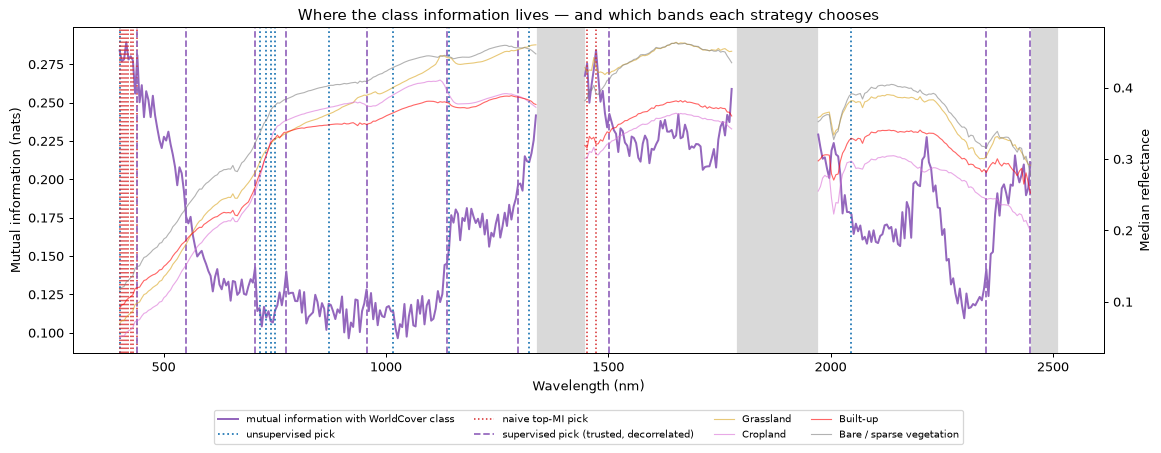

In [14]:
fig, ax = plt.subplots(figsize=(13, 5.2))
hu.plot_spectrum(ax, wl, mi, color="tab:purple", lw=1.6, label="mutual information with WorldCover class")
ax.set_ylabel("Mutual information (nats)"); ax.set_xlabel("Wavelength (nm)")
ax2 = ax.twinx()
for c, col in zip(classes, ("goldenrod", "orchid", "red", "gray")):
    hu.plot_spectrum(ax2, wl, np.median(Xs[ys == c], axis=0), color=col, lw=0.9, alpha=0.6,
                     label=hu.WORLDCOVER_CLASSES[c][0])
ax2.set_ylabel("Median reflectance")
for i, b in enumerate(unsup_bands):
    ax.axvline(wl[b], color="tab:blue", ls=":", lw=1.4, label="unsupervised pick" if i == 0 else None)
for i, b in enumerate(naive_bands):
    ax.axvline(wl[b], color="tab:red", ls=":", lw=1.2, label="naive top-MI pick" if i == 0 else None)
for i, b in enumerate(sup_bands):
    ax.axvline(wl[b], color="tab:purple", ls="--", lw=1.4, label="supervised pick (trusted, decorrelated)" if i == 0 else None)
hu.shade_bad_regions(ax)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.16))
ax.set_title("Where the class information lives — and which bands each strategy chooses")
plt.tight_layout(); plt.show()

### 5.1 Does it work? A quick test with a random forest

We train the same classifier on all 352 bands, on three sets of 10 selected bands (naive MI, constrained MI, unsupervised), on 10 *evenly spaced* bands as a baseline, and on 10 PCA and 10 MNF components.

> ⚠️ We use a simple random train/test split here. Neighbouring pixels are very similar, so this **overestimates** accuracy. Notebook 21 shows the correct *spatial* validation. The comparison *between* feature sets is still informative.

In [15]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import time

pca_l = PCA(n_components=10, random_state=SEED).fit(Xs)
mnf_m, T_l, _ = mnf_fit(Xs, Sigma_N)
even = np.linspace(0, n_bands - 1, 10).astype(int)
feature_sets = {
    "all 352 bands": Xs,
    "10 naive top-MI bands": Xs[:, naive_bands],
    "10 MI bands, constrained": Xs[:, sup_bands],
    "10 unsupervised bands": Xs[:, unsup_bands],
    "10 evenly spaced bands": Xs[:, even],
    "10 PCA components": pca_l.transform(Xs),
    "10 MNF components": ((Xs - mnf_m) @ T_l)[:, :10],
}
tr, te = train_test_split(np.arange(len(ys)), test_size=0.3, random_state=SEED, stratify=ys)
results = {}
for name, F in feature_sets.items():
    t0 = time.perf_counter()
    rf = RandomForestClassifier(n_estimators=150, n_jobs=4, random_state=SEED).fit(F[tr], ys[tr])
    results[name] = (accuracy_score(ys[te], rf.predict(F[te])), F.shape[1], time.perf_counter() - t0)
for name, (acc, d, t) in results.items():
    print(f"{name:24s} {d:4d} features   accuracy {acc:.3f}   ({t:.1f} s)")

all 352 bands             352 features   accuracy 0.870   (1.0 s)
10 naive top-MI bands      10 features   accuracy 0.695   (0.2 s)
10 MI bands, constrained   10 features   accuracy 0.869   (0.2 s)
10 unsupervised bands      10 features   accuracy 0.835   (0.2 s)
10 evenly spaced bands     10 features   accuracy 0.849   (0.2 s)
10 PCA components          10 features   accuracy 0.900   (0.2 s)
10 MNF components          10 features   accuracy 0.859   (0.2 s)


With only **10 of 352 features**, the constrained MI bands and the PCA/MNF components match or even beat the full spectrum (a small-scale Hughes effect), and training is much faster. The **naive top-MI bands do worst**: ten nearly identical noisy bands carry little more information than one. WorldCover's classes are broad (grassland vs cropland vs bare), and much of the remaining confusion is label noise, not missing spectral information. Don't over-interpret differences of 1–2 %.

## 6. Derivative spectra and the red-edge position

Derivatives emphasise the **shape** of a spectrum rather than its brightness. They suppress additive offsets such as soil background or residual haze and sharpen overlapping features. Derivatives amplify noise, so always smooth first, typically with a **Savitzky–Golay** filter (Savitzky & Golay, 1964).

The best-known derivative feature is the **red-edge position (REP)**: the wavelength of steepest slope between the red chlorophyll absorption and the NIR plateau. It shifts to *longer* wavelengths as chlorophyll content increases (a "red shift") and to shorter wavelengths under stress. Two ways to compute it:

- **Maximum first derivative** between 680 and 760 nm
- **Linear four-point interpolation** (Guyot & Baret, 1988), robust and cheap:

$$R_{re} = \frac{R_{670} + R_{780}}{2}, \qquad \text{REP} = 700 + 40\,\frac{R_{re} - R_{700}}{R_{740} - R_{700}}$$

In [16]:
from scipy.signal import savgol_filter

sel = (wl >= 650) & (wl <= 800)
wl_re = wl[sel]
seg = np.nan_to_num(cube[sel], nan=0.0)
smooth = savgol_filter(seg, window_length=7, polyorder=2, axis=0)
d1 = np.gradient(smooth, wl_re, axis=0)                     # first derivative (per nm)
in_edge = (wl_re >= 680) & (wl_re <= 760)
rep_max = wl_re[in_edge][np.argmax(d1[in_edge], axis=0)].astype("float32")
rep_lin = 700 + 40 * ((R(670) + R(780)) / 2 - R(700)) / (R(740) - R(700))
invalid = ~np.isfinite(ndvi) | (ndvi < 0.25)                # REP only meaningful for vegetation
rep_max[invalid] = np.nan
rep_lin = np.where(invalid, np.nan, rep_lin)
print(f"REP (linear) — 5th/50th/95th percentile over vegetated pixels: {np.nanpercentile(rep_lin, [5, 50, 95]).round(1)} nm")

REP (linear) — 5th/50th/95th percentile over vegetated pixels: [716.4 720.3 727.9] nm


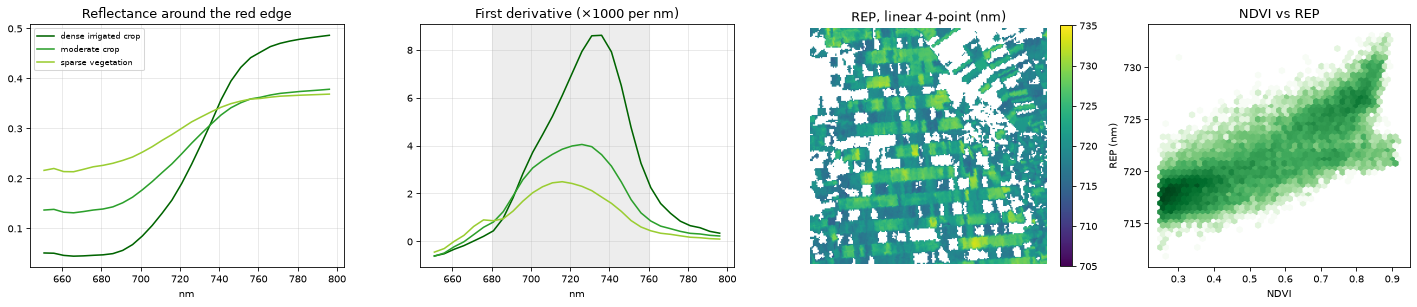

Agreement max-derivative vs linear REP: r = 0.87


In [17]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2), dpi=75, gridspec_kw={"width_ratios": [1.2, 1.2, 1, 1]})
# spectra and derivatives of three typical pixels
cases = {"dense irrigated crop": ndvi > 0.8, "moderate crop": (ndvi > 0.45) & (ndvi < 0.55),
         "sparse vegetation": (ndvi > 0.25) & (ndvi < 0.3)}
for (name, m), col in zip(cases.items(), ("darkgreen", "tab:green", "yellowgreen")):
    axes[0].plot(wl_re, np.nanmean(cube[sel][:, m], axis=1), color=col, label=name)
    axes[1].plot(wl_re, d1[:, m].mean(axis=1) * 1000, color=col, label=name)
axes[0].set_title("Reflectance around the red edge"); axes[0].set_xlabel("nm"); axes[0].legend(fontsize=8)
axes[1].set_title("First derivative (×1000 per nm)"); axes[1].set_xlabel("nm")
axes[1].axvspan(680, 760, color="0.93", zorder=0)
for ax in axes[:2]:
    ax.grid(alpha=0.3)
im = axes[2].imshow(rep_lin, cmap="viridis", vmin=705, vmax=735); axes[2].set_title("REP, linear 4-point (nm)")
plt.colorbar(im, ax=axes[2], fraction=0.046); axes[2].axis("off")
v = np.isfinite(rep_lin)
axes[3].hexbin(ndvi[v], rep_lin[v], gridsize=45, cmap="Greens", bins="log")
axes[3].set_xlabel("NDVI"); axes[3].set_ylabel("REP (nm)"); axes[3].set_title("NDVI vs REP")
plt.tight_layout(); plt.show()
print(f"Agreement max-derivative vs linear REP: r = {np.corrcoef(rep_max[v], rep_lin[v])[0, 1]:.2f}")

The derivative peak moves to longer wavelengths as the canopy gets denser (the red shift). The NDVI–REP plot shows the classic **saturation** of NDVI: between NDVI 0.75 and 0.9, REP still spans more than 10 nm, so it keeps separating canopies that NDVI calls "the same". The two branches at high NDVI are fields of different crops or growth stages. That's why red-edge features are popular for nitrogen and crop-stress monitoring. The max-derivative REP comes in 5 nm steps (one Tanager band), so the interpolated linear REP gives a smoother map.

## 7. Narrow-band indices: what only a hyperspectral sensor can see

The theme notebooks use broadband indices (NDVI, NDWI, NBR) that Sentinel-2 or Landsat can also compute. Hyperspectral data allows **narrow-band indices** that target specific pigments, water or dry matter:

| Index | Formula | Sensitive to | Reference | From Sentinel-2? |
|---|---|---|---|---|
| **PRI** | $(R_{531} - R_{570}) / (R_{531} + R_{570})$ | xanthophyll cycle, light-use efficiency, stress | Gamon et al., 1992 | ❌ no 531 nm band |
| **MCARI** | $[(R_{700} - R_{670}) - 0.2(R_{700} - R_{550})]\,(R_{700}/R_{670})$ | chlorophyll (reduced soil effect) | Daughtry et al., 2000 | ≈ with B3/B4/B5 (broad) |
| **TCARI/OSAVI** | $\frac{3[(R_{700}-R_{670}) - 0.2(R_{700}-R_{550})(R_{700}/R_{670})]}{1.16(R_{800}-R_{670})/(R_{800}+R_{670}+0.16)}$ | chlorophyll, insensitive to LAI | Haboudane et al., 2002 | ≈ (broad B5) |
| **CRI1** | $1/R_{510} - 1/R_{550}$ | carotenoids | Gitelson et al., 2002 | ❌ no 510 nm band |
| **ARI1** | $1/R_{550} - 1/R_{700}$ | anthocyanins (senescence, stress) | Gitelson et al., 2001 | ≈ (broad B3/B5) |
| **NDWI (Gao)** | $(R_{860} - R_{1240}) / (R_{860} + R_{1240})$ | canopy liquid water | Gao, 1996 | ❌ no 1240 nm band |
| **NDNI** | $\frac{\log(1/R_{1510}) - \log(1/R_{1680})}{\log(1/R_{1510}) + \log(1/R_{1680})}$ | canopy nitrogen | Serrano et al., 2002 | ❌ |
| **CAI** | $0.5(R_{2031} + R_{2211}) - R_{2101}$ | cellulose/lignin: crop residue, dry matter (non-green pixels only) | Nagler et al., 2003; Daughtry et al., 2005 | ❌ B12 is 175 nm wide |
| **Clay (Al-OH) depth** | $1 - R_{2205}/R_{cont}$ | kaolinite, illite, smectite | e.g. Clark et al., 2003 | ❌ |
| **Carbonate depth** | $1 - R_{2340}/R_{cont}$ | calcite, dolomite | e.g. Clark et al., 2003 | ❌ |

"≈" means a broadband approximation exists but is less specific.

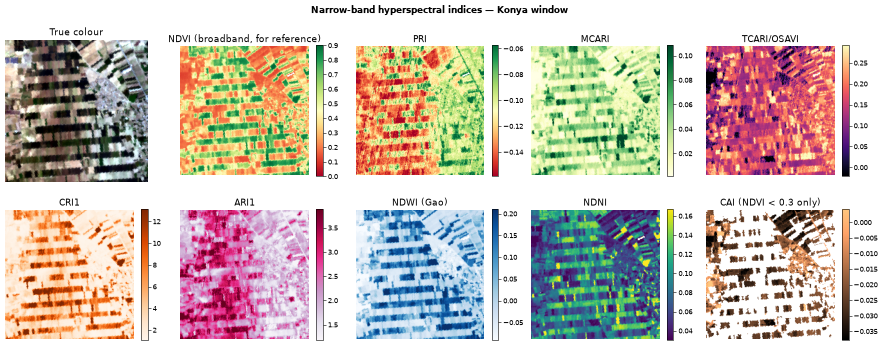

In [18]:
eps = 1e-6
osavi = 1.16 * (R(800) - R(670)) / (R(800) + R(670) + 0.16)
tcari = 3 * ((R(700) - R(670)) - 0.2 * (R(700) - R(550)) * (R(700) / (R(670) + eps)))
narrow = {
    "PRI": hu.nd(R(531), R(570)),
    "MCARI": ((R(700) - R(670)) - 0.2 * (R(700) - R(550))) * (R(700) / (R(670) + eps)),
    "TCARI/OSAVI": tcari / (osavi + eps),
    "CRI1": 1 / R(510) - 1 / R(550),
    "ARI1": 1 / R(550) - 1 / R(700),
    "NDWI (Gao)": hu.nd(R(860), R(1240)),
    "NDNI": (np.log(1 / R(1510)) - np.log(1 / R(1680))) / (np.log(1 / R(1510)) + np.log(1 / R(1680))),
    "CAI": 0.5 * (R(2031) + R(2211)) - R(2101),     # bands chosen to avoid the CO2 absorption near 2010 nm
}
narrow_display = dict(narrow)
narrow_display["CAI"] = np.where(ndvi < 0.3, narrow["CAI"], np.nan)   # CAI is only meaningful without green canopy
fig, axes = plt.subplots(2, 5, figsize=(17, 7.0), dpi=52)
axes = axes.ravel()
axes[0].imshow(hu.rgb_from_cube(cube, wl)); axes[0].set_title("True colour")
im = axes[1].imshow(ndvi, cmap="RdYlGn", vmin=0, vmax=0.9); axes[1].set_title("NDVI (broadband, for reference)")
plt.colorbar(im, ax=axes[1], fraction=0.046)
cmaps = {"PRI": "RdYlGn", "MCARI": "YlGn", "TCARI/OSAVI": "magma", "CRI1": "Oranges", "ARI1": "PuRd",
         "NDWI (Gao)": "Blues", "NDNI": "viridis", "CAI": "copper"}
for ax, (name, img) in zip(axes[2:], narrow_display.items()):
    lo, hi = np.nanpercentile(img, [2, 98])
    im = ax.imshow(img, cmap=cmaps[name], vmin=lo, vmax=hi); ax.set_title(name if name != "CAI" else "CAI (NDVI < 0.3 only)")
    plt.colorbar(im, ax=ax, fraction=0.046)
for ax in axes:
    ax.axis("off")
plt.suptitle("Narrow-band hyperspectral indices — Konya window", fontweight="bold")
plt.tight_layout(); plt.show()

**Interpretation.**
- **CAI** must be read on **non-green pixels only** (green canopies are masked in the map): in green leaves, liquid-water absorption dominates the 2000–2200 nm shape. Among the bare and fallow fields, higher (less negative) CAI marks **dry crop residue and stubble**. Cellulose and lignin absorb near 2100 nm and flatten the soil's reflectance hump there. The differences are small (~0.02 reflectance), and separating residue from bare soil is essentially impossible with broadband sensors, yet it matters for conservation agriculture and erosion risk.
- **NDWI (Gao)** follows canopy water: highest on the irrigated strips.
- **TCARI/OSAVI** is designed to track chlorophyll while ignoring canopy density, so it looks different from NDVI. Low values mean more chlorophyll per unit of greenness.
- **PRI** is a physiological signal (light-use efficiency) and is noisy from space. Compare it only within the same crop and the same scene.

### 7.1 Mineral absorption depths: clay and carbonate

Minerals have narrow **vibrational absorption features** in the SWIR: the Al–OH bond in clays (kaolinite, illite, smectite) near **2200 nm**, and the CO₃ group in carbonates (calcite ≈ 2340 nm, dolomite ≈ 2320 nm). The **band depth** measures how deep the feature is relative to a straight-line continuum between two shoulders:

$$D = 1 - \frac{R_{center}}{R_{continuum}}, \qquad R_{continuum} = R_L + \frac{\lambda_c - \lambda_L}{\lambda_R - \lambda_L}(R_R - R_L)$$

We map both depths over three scenes. Vegetation (NDVI > 0.3) and water (NDWI > 0) are masked because they have their own SWIR shapes. For Al Dhafra we switch the cloud mask off, since it wrongly flags the bright sabkha (notebook 11).

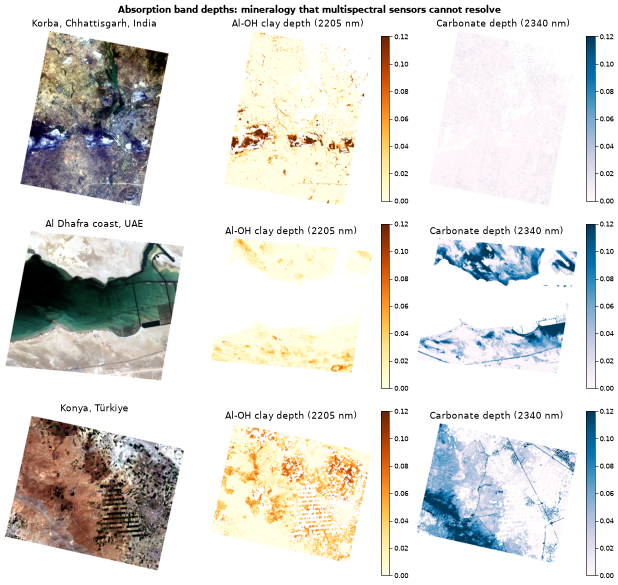

In [19]:
def depth_map(sc, left, center, right, stride=1):
    """Band depth from three bands (full scene, cloud mask off), vegetation and water masked."""
    RL, RC, RR = (sc.read_band(nm, stride=stride, cloud=False) for nm in (left, center, right))
    wl_l, wl_c, wl_r = (sc.wavelengths[sc.band_index(nm)] for nm in (left, center, right))
    cont = RL + (wl_c - wl_l) / (wl_r - wl_l) * (RR - RL)
    D = 1 - RC / (cont + 1e-9)
    ndvi_ = hu.nd(sc.read_band(860, stride=stride, cloud=False), sc.read_band(665, stride=stride, cloud=False))
    ndwi_ = hu.nd(sc.read_band(560, stride=stride, cloud=False), sc.read_band(860, stride=stride, cloud=False))
    D[(ndvi_ > 0.3) | (ndwi_ > 0)] = np.nan
    return D

CLAY = (2120, 2205, 2250)
CARB = (2270, 2340, 2390)
mineral_scenes = ["20250219_053251_31_4001", "20250511_074311_00_4001", "20250608_091605_90_4001"]
maps = {}
for sid in mineral_scenes:
    sc = hu.get_scene(sid)
    maps[sid] = {"rgb": sc.rgb(stride=2), "clay": depth_map(sc, *CLAY, stride=2), "carb": depth_map(sc, *CARB, stride=2)}

fig, axes = plt.subplots(3, 3, figsize=(12, 11.5), dpi=52)
for row, sid in zip(axes, mineral_scenes):
    rgb = maps[sid]["rgb"].copy(); rgb[np.isnan(rgb)] = 1
    row[0].imshow(rgb); row[0].set_title(hu.SCENES[sid]["place"])
    for ax, key, title, cm in ((row[1], "clay", "Al-OH clay depth (2205 nm)", "YlOrBr"),
                               (row[2], "carb", "Carbonate depth (2340 nm)", "PuBu")):
        im = ax.imshow(maps[sid][key], cmap=cm, vmin=0, vmax=0.12)
        ax.set_title(title); plt.colorbar(im, ax=ax, fraction=0.046)
    for ax in row:
        ax.axis("off")
plt.suptitle("Absorption band depths: mineralogy that multispectral sensors cannot resolve", fontweight="bold")
plt.tight_layout(); plt.show()

Three clear, geologically sensible patterns emerge:
- **Korba (India):** strong **clay** absorption on the overburden dumps of the open-cast **coal mines**. The Gondwana sandstones and shales moved during mining are rich in kaolinite.
- **Al Dhafra (UAE):** strong **carbonate** absorption along the coast. The Gulf's coastal sediments and sabkhas are made of carbonate sand and mud.
- **Konya (Türkiye):** **carbonate**-rich soils in the west. The Konya plain is an ancient lake basin with calcareous (marl) deposits.

Let's confirm with **continuum-removed spectra** (notebook 10) of the pixels with the deepest features, compared with typical pixels.

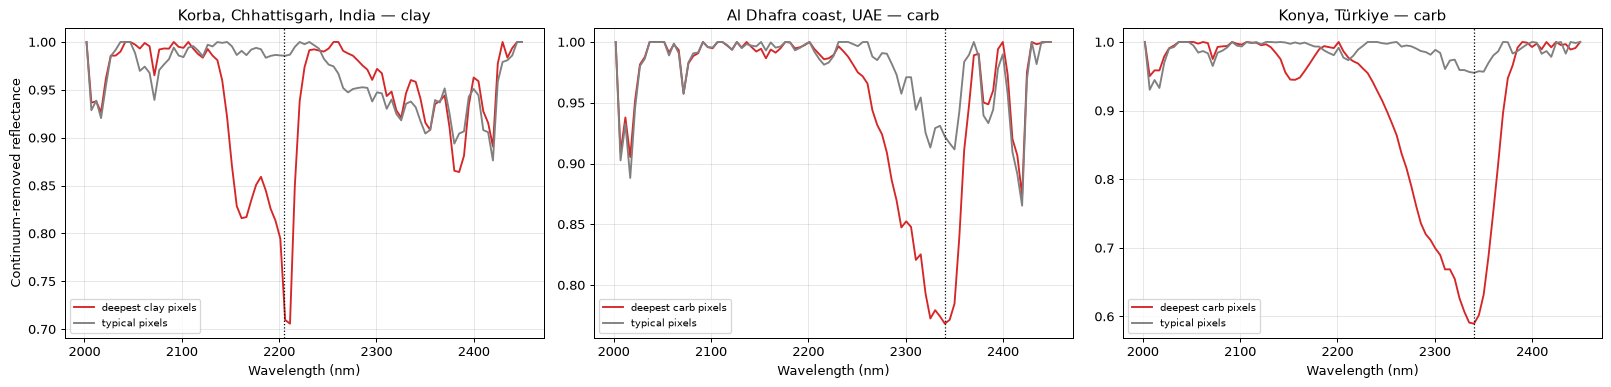

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.4))
for ax, (sid, key, feat) in zip(axes, (("20250219_053251_31_4001", "clay", CLAY),
                                       ("20250511_074311_00_4001", "carb", CARB),
                                       ("20250608_091605_90_4001", "carb", CARB))):
    sc = hu.get_scene(sid)
    D = maps[sid][key]
    top = np.argsort(np.nan_to_num(D.ravel(), nan=-1))[-50:]              # 50 deepest pixels (stride-2 grid)
    rr, cc = np.unravel_index(top, D.shape)
    spec_top = np.nanmean([sc.read_pixel(r * 2, c * 2)[0] for r, c in zip(rr, cc)], axis=0)
    med_row, med_col = np.unravel_index(np.argsort(np.nan_to_num(np.abs(D - np.nanmedian(D)).ravel(), nan=9))[:50], D.shape)
    spec_med = np.nanmean([sc.read_pixel(r * 2, c * 2)[0] for r, c in zip(med_row, med_col)], axis=0)
    wl_g = sc.wavelengths[sc.good_bands]
    m = (wl_g > 2000) & (wl_g < 2450)
    ax.plot(wl_g[m], hu.continuum_removed(wl_g[m], spec_top[m]), color="tab:red", label=f"deepest {key} pixels")
    ax.plot(wl_g[m], hu.continuum_removed(wl_g[m], spec_med[m]), color="0.5", label="typical pixels")
    ax.axvline(feat[1], color="k", ls=":", lw=1)
    ax.set_title(f"{hu.SCENES[sid]['place']} — {key}"); ax.set_xlabel("Wavelength (nm)"); ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Continuum-removed reflectance")
plt.tight_layout(); plt.show()

The shapes confirm the minerals. Korba's clay pixels show the characteristic **kaolinite doublet** at ~2165 and ~2205 nm. The Al Dhafra and Konya pixels show the broad, asymmetric **carbonate** feature centred near 2335–2340 nm (calcite). The small wiggles around 2000–2080 nm, present in *all* spectra, are residual CO₂ absorption from the atmospheric correction, not surface features.

### 7.2 What would Sentinel-2 see?

We resample the Konya carbonate-soil spectrum and an irrigated-crop spectrum to Sentinel-2's bands with Gaussian response functions. The **2340 nm carbonate feature lies inside the 175 nm-wide band B12**, so Sentinel-2 averages it away. The same happens to the 2100 nm cellulose feature, the 1240 nm water band and the 531 nm PRI band.

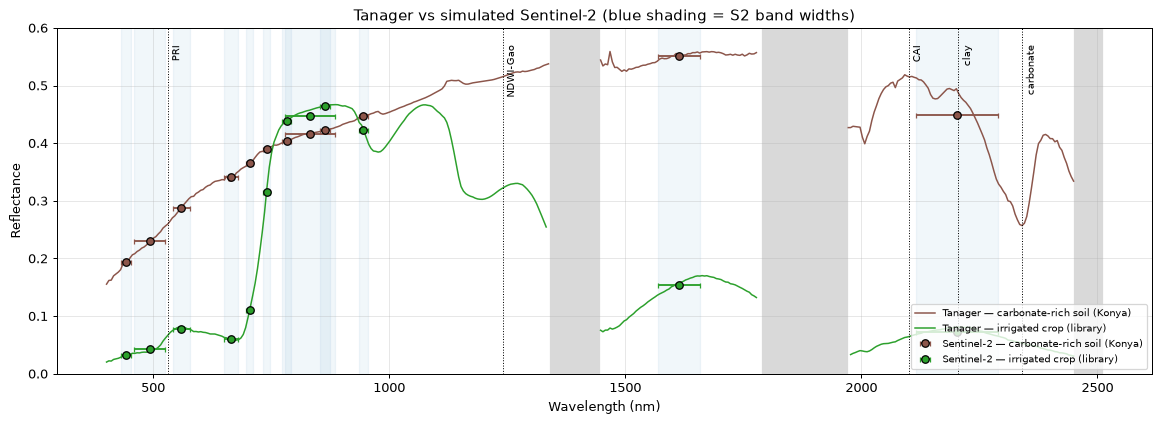

In [21]:
lib_wl, lib, _ = hu.load_library()
konya = hu.get_scene("20250608_091605_90_4001")
D = maps["20250608_091605_90_4001"]["carb"]
rr, cc = np.unravel_index(np.argsort(np.nan_to_num(D.ravel(), nan=-1))[-50:], D.shape)
carb_soil = np.nanmean([konya.read_pixel(r * 2, c * 2)[0] for r, c in zip(rr, cc)], axis=0)
wl_g = konya.wavelengths[konya.good_bands]
crop = np.interp(wl_g, lib_wl, lib["irrigated_crop"])

s2_c = np.array([v[0] for v in hu.SENTINEL2_BANDS.values()])
s2_w = np.array([v[1] for v in hu.SENTINEL2_BANDS.values()])
fig, ax = plt.subplots(figsize=(13, 4.8))
for spec, col, name in ((carb_soil, "tab:brown", "carbonate-rich soil (Konya)"), (crop, "tab:green", "irrigated crop (library)")):
    hu.plot_spectrum(ax, wl_g, spec, color=col, lw=1.2, label=f"Tanager — {name}")
    s2 = hu.resample_to_sensor(wl_g, spec, s2_c, s2_w)
    ax.errorbar(s2_c, s2, xerr=s2_w / 2, fmt="o", color=col, mec="k", capsize=2, label=f"Sentinel-2 — {name}")
for name, (c, w) in hu.SENTINEL2_BANDS.items():
    ax.axvspan(c - w / 2, c + w / 2, color="tab:blue", alpha=0.06)
for nm, lab in ((531, "PRI"), (1240, "NDWI-Gao"), (2100, "CAI"), (2205, "clay"), (2340, "carbonate")):
    ax.axvline(nm, color="k", ls=":", lw=0.8); ax.text(nm + 8, 0.57, lab, rotation=90, fontsize=8, va="top")
hu.shade_bad_regions(ax)
ax.set_ylim(0, 0.6); ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("Reflectance"); ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="lower right"); ax.set_title("Tanager vs simulated Sentinel-2 (blue shading = S2 band widths)")
plt.tight_layout(); plt.show()

## 8. The feature stack

Now we put the most useful features together into a compact, **interpretable** stack for the Konya window:

| Group | Features |
|---|---|
| Extracted (noise-aware) | MNF 1–8 |
| Vegetation physiology | NDVI, REP, TCARI/OSAVI, PRI, NDWI (Gao) |
| Dry matter / soil | CAI, clay depth, carbonate depth |

That's 16 features instead of 352 bands, and each one has a physical meaning. We save it as a GeoTIFF with band names, which notebook 15 can use as classifier input.

Saved 16 features × 200 × 200 px → konya_feature_stack.tif


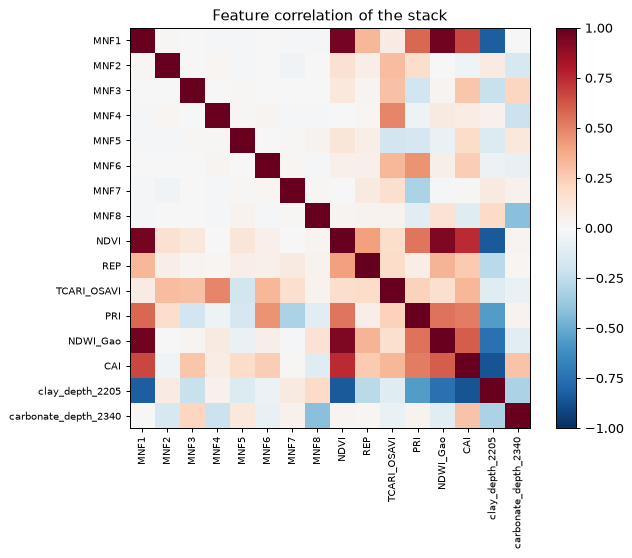

In [22]:
clay_w = hu.band_depth(wl, cube, *CLAY)
carb_w = hu.band_depth(wl, cube, *CARB)
features = {f"MNF{k + 1}": hu.pixels_to_image(Z_mnf[:, k], ok) for k in range(8)}
# REP is undefined without vegetation: fill non-vegetated (but valid) pixels with 700 nm so classifiers get no NaNs
rep_filled = np.where(np.isfinite(ndvi), np.nan_to_num(rep_lin, nan=700.0), np.nan)
features.update({"NDVI": ndvi, "REP": rep_filled,
                 "TCARI_OSAVI": narrow["TCARI/OSAVI"], "PRI": narrow["PRI"], "NDWI_Gao": narrow["NDWI (Gao)"],
                 "CAI": narrow["CAI"], "clay_depth_2205": clay_w, "carbonate_depth_2340": carb_w})
names = list(features)
stack = np.stack([features[n] for n in names]).astype("float32")

out_dir = hu.ensure_output_dir("13")
tif = hu.save_geotiff(out_dir / "konya_feature_stack.tif", stack, scene.transform(WINDOW), scene.crs, band_names=names)
np.savez_compressed(out_dir / "konya_feature_stack.npz", stack=stack, names=np.array(names), window=np.array(WINDOW))
print(f"Saved {stack.shape[0]} features × {stack.shape[1]} × {stack.shape[2]} px → {tif.name}")

Fs, okf = hu.cube_to_pixels(np.nan_to_num(stack, nan=0.0))
Cf = np.corrcoef(Fs[rng.choice(len(Fs), 5000, replace=False)], rowvar=False)
fig, ax = plt.subplots(figsize=(7.5, 6.3))
im = ax.imshow(Cf, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=90, fontsize=8)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=8)
plt.colorbar(im, ax=ax, fraction=0.046); ax.set_title("Feature correlation of the stack")
plt.tight_layout(); plt.show()

The stack is much less redundant than 352 raw bands. MNF components are uncorrelated by construction. Some redundancy remains: MNF1, NDVI, NDWI (Gao) and CAI all respond to green vegetation, and clay depth is negatively correlated with them because green canopies mask the soil's 2205 nm feature. That's fine for a classifier. For *interpretation*, pick one representative per group. (REP is set to 700 nm for non-vegetated pixels so the stack has no gaps.)

## ✏️ Your turn

**1. Standardised PCA.** Repeat section 3 after standardising every band to zero mean and unit variance (`sklearn.preprocessing.StandardScaler`). How do the explained-variance curve and the PC1 loadings change? Why?

<details><summary>Hint</summary>

Without standardisation, bright NIR/SWIR bands dominate the variance. After scaling, every band counts equally, so low-reflectance visible bands have more influence.
</details>

<details><summary>Solution</summary>

```python
from sklearn.preprocessing import StandardScaler
Xz = StandardScaler().fit_transform(X)
pca_z = PCA(n_components=30, random_state=SEED).fit(Xz)
print(np.round(pca_z.explained_variance_ratio_[:6] * 100, 2))
fig, ax = plt.subplots(); hu.plot_spectrum(ax, wl, pca_z.components_[0]); plt.show()
```
</details>

**2. How many MNF components?** Denoise with $K$ = 5, 20 and 80 and plot the "removed" image at 2440 nm for each. At what $K$ do you start removing real field structure?

**3. REP for stress detection.** Compute the REP for the El Salvador mangrove scene (`20250223_165546_32_4001`) and compare the median REP of mangroves (WorldCover class 95) with that of the sugar-cane cropland (class 40). Which one has the higher chlorophyll content according to REP?

<details><summary>Hint</summary>

Use `hu.load_labels("20250223_165546_32_4001", min_purity=9)` and the linear 4-point formula on `scene.read_band(...)` images.
</details>

**4. Your own index.** The **Normalised Difference Lignin Index** is $\text{NDLI} = \frac{\log(1/R_{1754}) - \log(1/R_{1680})}{\log(1/R_{1754}) + \log(1/R_{1680})}$ (Serrano et al., 2002). Compute it for the Konya window and compare it with CAI. Do they agree on where the dry residue is?

**5. Band budget.** Imagine a small satellite that can carry only **six** narrow bands. Using `mi_decorrelated` and the random-forest test from section 5, which six Tanager bands would you choose for crop-type mapping in Konya, and what accuracy do you lose compared with all bands?

## Key takeaways

- Hyperspectral bands are **highly redundant** (neighbour r > 0.99). With limited training data, too many features hurt (the **Hughes phenomenon**).
- **PCA** orders components by variance. Great for compression and visualisation, but variance ≠ information.
- **MNF** orders components by **signal-to-noise**, isolates sensor artefacts (detector striping) and enables **denoising**. Estimate noise in a homogeneous area and regularise the noise covariance.
- **Band selection** (unsupervised or MI-based) keeps interpretable physical bands. 10 well-chosen bands can match 352 for many tasks.
- **Derivatives and REP** capture spectral *shape*. REP keeps responding to chlorophyll after NDVI saturates.
- **Narrow-band indices and band depths** (PRI, CAI, NDWI-Gao, clay and carbonate depths) are what make hyperspectral data worth it. Most of them can't be computed from Sentinel-2.

**For your project:** start from a small, justified feature stack (like section 8) rather than all 352 bands. Explain *why* each feature is physically relevant to your use case. Reviewers value this more than a marginal accuracy gain.

**References:** Daughtry et al. (2005) *Agron. J.* 97:864 · Hughes (1968) *IEEE Trans. Inf. Theory* 14:55 · Green et al. (1988) *IEEE TGRS* 26:65 · Lee et al. (1990) *IEEE TGRS* 28:295 · Savitzky & Golay (1964) *Anal. Chem.* 36:1627 · Guyot & Baret (1988) *Proc. 4th Int. Coll. Spectral Signatures* · Gamon et al. (1992) *RSE* 41:35 · Daughtry et al. (2000) *RSE* 74:229 · Haboudane et al. (2002) *RSE* 81:416 · Gitelson et al. (2001, 2002) *Photochem. Photobiol.* · Gao (1996) *RSE* 58:257 · Serrano et al. (2002) *RSE* 81:355 · Nagler et al. (2003) *RSE* 87:310 · Peng et al. (2005) *IEEE TPAMI* 27:1226 · Clark et al. (2003) *JGR* 108(E12):5131

---
> 📖 Data: Tanager — CC-BY-4.0 © Planet Labs PBC · ESA WorldCover 2021 v200 — CC-BY 4.0